# 04_peerj: PeerJ

PeerJ publishes the raw data of every article as supplementary files; found through Europe PMC.

**How the journal datasets were found.** Europe PMC was searched for every open-access paper with supplementary files whose title/abstract mentions Toxoplasma, toxoplasmosis, gondii, TORCH, multiplex serology or pathogen burden (3,482 papers). Their data files (xlsx, xls, csv, sav, dta, ...) were downloaded from the PMC Open Access S3 bucket (1,407 papers had data files, 6.6 GB) and every table with >= 80 rows was scanned for a Toxoplasma result column (607 tables, 285 papers). Human, participant-level tables with at least two IgG classes were then checked by hand. Scripts: `datasets/_harvest/`.

**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.

**Sections:** setup → helpers → one section per dataset (where it comes from, how the label is coded, what is removed) → build and evaluate → chart. Outputs are written to `raw/`, `processed/`, `results.csv`, `DATASETS.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
%run -i datasets/common/protocol.ipynb
%run -i datasets/common/folder_tools.ipynb
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/04_peerj'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


**Notes on this source.** PeerJ: participant-level supplementary data (PeerJ requires raw data with every article).

## Helpers (curated loaders and source-specific functions)

In [2]:
import numpy as np


import pandas as pd


import external_datasets as ex


def leukemia_children():
    """Patients and controls are on two sheets with different column names: harmonise and stack."""
    p = 'datasets/04_peerj/raw/peerj-07-6604-s001.xls'
    yes = lambda s: np.where(s.isna(), np.nan, s.astype(str).str.strip().str.lower().isin(['yes', '1', 'y']).astype(float))
    out = []
    for sheet, leuk in [(' leukemia Children', 1.0), ('Control', 0.0)]:
        d = read_table(p, sheet)
        col = lambda *keys: next(c for c in d.columns if all(k in c.lower() for k in keys))
        out.append(pd.DataFrame({
            'leukemia': leuk, 'male': yes(d[col('gender')].astype(str).str.lower().replace({'male': 'yes', 'female': 'no'})),
            'age': pd.to_numeric(d[col('age')], errors='coerce'), 'rural': yes(d[col('residence')].astype(str).str.lower().replace({'rural': 'yes', 'urban': 'no'})),
            'cat_contact': yes(d[col('cat')]), 'dog_contact': yes(d[col('dog')]), 'pig_contact': yes(d[col('pig' if leuk else 'swine')]),
            'raw_vegetables': yes(d[col('raw vegetables')]), 'raw_meat': yes(d[col('raw/undercooked meat')]),
            'soil_exposure': yes(d[col('soil')]), 'drinking_water': d[col('drinking water')].astype(str),
            'parent_occupation': d[col('occupation')].astype(str), 'y': yes(d['IgG'])}))
    d = pd.concat(out, ignore_index=True)
    return d.drop(columns='y'), d['y'].astype(int)

## Datasets

Each cell adds one dataset to `CONFIG`: `source` = where the raw file comes from, `label` / `pos` / `neg` = how the Toxoplasma IgG result is coded, `drop` = extra columns removed (leakage, identifiers, outcomes), `loader` = a hand-written loader in `scripts/` for datasets curated earlier.

In [3]:
CONFIG = []

### china_gynaecological_tumour

**T. gondii in women with a gynaecological tumour and controls, eastern China**  
China · Women with gynaecological tumours + matched controls · DOI/ID: `10.7717/peerj.14569`

In [4]:
CONFIG.append(dict(key='china_gynaecological_tumour', title='T. gondii in women with a gynaecological tumour and controls, eastern China',
     doi='10.7717/peerj.14569', setting='Women with gynaecological tumours + matched controls', country='China',
     source=('pmc', 'PMC9760017'), file='peerj-10-14569-s001.xlsx', loader=ex.china_women))

### china_leukemia_children

**Seroprevalence and risk factors of T. gondii in children with leukaemia, Shandong**  
China · Children with leukaemia + matched controls · DOI/ID: `10.7717/peerj.6604`

Two sheets (patients / controls) harmonised; direct exposures: cats, dogs, pigs, raw meat, raw vegetables, soil, water.

In [5]:
CONFIG.append(dict(key='china_leukemia_children', title='Seroprevalence and risk factors of T. gondii in children with leukaemia, Shandong',
     doi='10.7717/peerj.6604', setting='Children with leukaemia + matched controls', country='China',
     source=('pmc', 'PMC6420808'), file='peerj-07-6604-s001.xls', loader=leukemia_children,
     note='Two sheets (patients / controls) harmonised; direct exposures: cats, dogs, pigs, raw meat, raw vegetables, soil, water.'))

## Build and evaluate

Downloads (or copies) each raw file into `raw/`, builds `processed/<dataset>.csv`, removes leakage columns, then runs logistic regression, random forest and XGBoost with 5-fold x 3 cross-validation.

In [6]:
res = run(HERE, CONFIG)

china_gynaecological_tumour        n=   920 pos=   69 feats= 12 best AUC=0.892 (RandomForest)


china_leukemia_children            n=   678 pos=   79 feats= 11 best AUC=0.588 (XGBoost)


In [7]:
cols = ['dataset', 'country', 'n', 'positives', 'prevalence', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc',
        'best_auc', 'best_model']
res[[c for c in cols if c in res]]

,dataset,country,n,positives,prevalence,n_features,LogReg_auc,RandomForest_auc,XGBoost_auc,best_auc,best_model
0,china_gynaecological_tumour,China,920,69,0.075,12,0.839,0.892,0.877,0.892,RandomForest
1,china_leukemia_children,China,678,79,0.117,11,0.544,0.584,0.588,0.588,XGBoost


## Chart

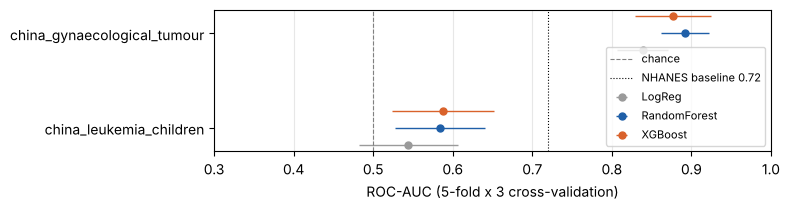

In [8]:
# ROC-AUC per dataset and model (error bars: SD over the 15 CV folds)
import matplotlib.pyplot as plt
r = res[res.best_auc.notna()].sort_values('best_auc')
if len(r):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(r) + 1.2))
    for k, (m, c) in enumerate([('LogReg', '#9a9a9a'), ('RandomForest', '#1f5fa8'), ('XGBoost', '#d9622b')]):
        ax.errorbar(r[f'{m}_auc'], [i + (k - 1) * 0.18 for i in range(len(r))], xerr=r[f'{m}_sd'], fmt='o', ms=5,
                    color=c, label=m, elinewidth=1)
    ax.axvline(0.5, ls='--', color='grey', lw=0.8, label='chance')
    ax.axvline(0.72, ls=':', color='black', lw=0.8, label='NHANES baseline 0.72')
    ax.set_yticks(range(len(r))); ax.set_yticklabels(r.dataset)
    ax.set_xlabel('ROC-AUC (5-fold x 3 cross-validation)'); ax.set_xlim(0.3, 1.0)
    ax.legend(loc='lower right', fontsize=8); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout(); plt.show()

## What was removed as leakage, and the inputs used

In [9]:
res[['dataset', 'removed_as_leakage', 'features']]

,dataset,removed_as_leakage,features
0,china_gynaecological_tumour,,"age, tumour_patient, rural, cat_contact, dog_contact, sw..."
1,china_leukemia_children,,"leukemia, age, rural, cat_contact, dog_contact, pig_cont..."
